## TP2 : Prétraitement avancé d’un jeu de données en Machine Learning

## Partie 1 — Explorer et vérifier les données


## Question 1 : Chargement et exploration

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("transactions_TP2.csv")

In [4]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [5]:
df.shape

(3045, 12)

In [6]:
df.dtypes

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object

## Question 2 : Calculer le nombre et le pourcentage des valeurs manquantes

In [7]:
missing = pd.DataFrame({"Nombre_manquant": df.isnull().sum(),"Pourcentage": (df.isnull().sum() / len(df)) * 100})
missing = missing.sort_values(by="Pourcentage",ascending=False)
missing

,Nombre_manquant,Pourcentage
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


## Question 3 : Rechercher les opérations répétées avec id_operation

In [8]:
df["id_operation"].duplicated().sum()

np.int64(45)

In [9]:
df = df.drop_duplicates(subset="id_operation")

In [10]:
print("Nombre de doublons :", df["id_operation"].duplicated().sum())
print("Dimensions après suppression :", df.shape)

Nombre de doublons : 0
Dimensions après suppression : (3000, 12)


## Question 4 : Tracer un histogramme et un boxplot de montant_dh

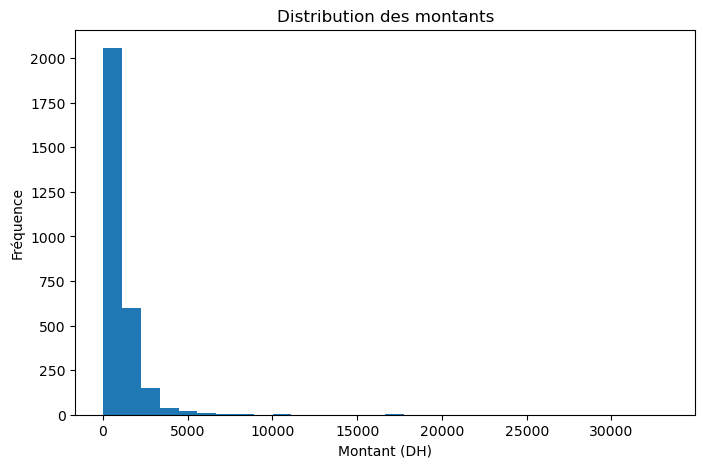

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(df["montant_dh"].dropna(), bins=30)
plt.title("Distribution des montants")
plt.xlabel("Montant (DH)")
plt.ylabel("Fréquence")
plt.show()

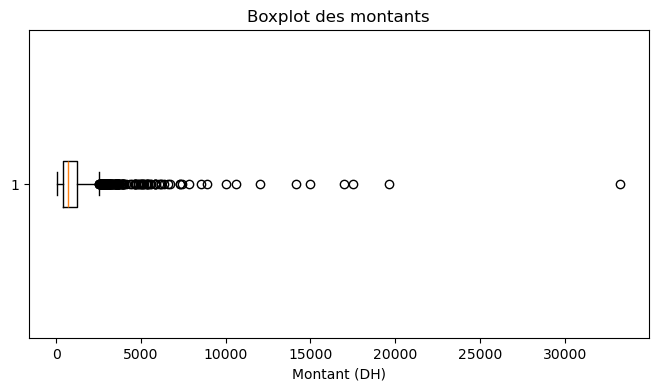

In [12]:
plt.figure(figsize=(8, 4))
plt.boxplot(df["montant_dh"].dropna(), vert=False)
plt.title("Boxplot des montants")
plt.xlabel("Montant (DH)")
plt.show()

## Question 5 : Calculer la proportion des fraudes et tracer un diagramme

In [13]:
df["fraude"].value_counts()

fraude
0    2742
1     258
Name: count, dtype: int64

In [14]:
df["fraude"].value_counts(normalize=True) * 100

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64

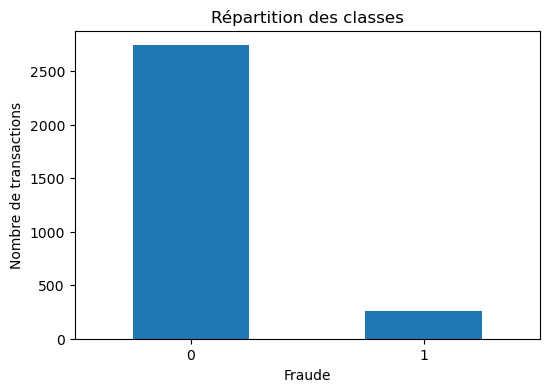

In [15]:
df["fraude"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)
plt.title("Répartition des classes")
plt.xlabel("Fraude")
plt.ylabel("Nombre de transactions")
plt.xticks(rotation=0)
plt.show()

## Question 6 : Identifier les identifiants et resultat_enquete

On connaît resultat_enquete après la réalisation de l'enquête sur la transaction

# Partie 2 — Préparer les données sans fuite

## Question 7 : Créer X et y

In [16]:
X = df.drop(columns=[
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])
y = df["fraude"]

## Question 8 : Diviser les données en deux groupes (80% / 20%)

In [17]:
from sklearn.model_selection import train_test_split
X_ref, X_verif, y_ref, y_verif = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
print("Proportion dans le groupe de référence :")
print(y_ref.value_counts(normalize=True) * 100)

print("\nProportion dans le groupe de vérification :")
print(y_verif.value_counts(normalize=True) * 100)

Proportion dans le groupe de référence :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Proportion dans le groupe de vérification :
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


## Question 9 : Lister les variables numériques et catégorielles

In [19]:
numeriques = X_ref.select_dtypes(include=["int64", "float64"]).columns
categorielle = X_ref.select_dtypes(include=["object"]).columns
print("Variables numériques :", list(numeriques))
print("Variables catégorielles :", list(categorielle))

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


## Question 10 : Construire un pipeline pour les variables numériques

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [21]:
numeriques = X_ref.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
print(numeriques)

['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']


In [22]:
pipeline_num = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [23]:
X_ref_num = pipeline_num.fit_transform(X_ref[numeriques])
X_verif_num = pipeline_num.transform(X_verif[numeriques])

In [24]:
print("X_ref_num :", X_ref_num.shape)
print("X_verif_num :", X_verif_num.shape)

X_ref_num : (2400, 4)
X_verif_num : (600, 4)


## Question 11 : Construire un pipeline pour les variables catégorielles

In [25]:
from sklearn.preprocessing import OneHotEncoder

In [26]:
categorielle = X_ref.select_dtypes(
    include=["object"]
).columns.tolist()
print(categorielle)

['canal', 'appareil', 'region', 'international']


In [27]:
pipeline_cat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [28]:
X_ref_cat = pipeline_cat.fit_transform(X_ref[categorielle])
X_verif_cat = pipeline_cat.transform(X_verif[categorielle])

In [29]:
print("X_ref_cat :", X_ref_cat.shape)
print("X_verif_cat :", X_verif_cat.shape)

X_ref_cat : (2400, 14)
X_verif_cat : (600, 14)


## Question 12 : Réunir les deux pipelines avec ColumnTransformer

In [30]:
from sklearn.compose import ColumnTransformer

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", pipeline_num, numeriques),
        ("cat", pipeline_cat, categorielle)
    ]
)

In [32]:
X_ref_final = preprocessor.fit_transform(X_ref)
X_verif_final = preprocessor.transform(X_verif)

print("Avant transformation :")
print("X_ref :", X_ref.shape)
print("X_verif :", X_verif.shape)
print("\nAprès transformation :")
print("X_ref_final :", X_ref_final.shape)
print("X_verif_final :", X_verif_final.shape)

## Question 13 : Remplacer StandardScaler par RobustScaler

In [33]:
from sklearn.preprocessing import RobustScaler

In [34]:
pipeline_num_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

In [35]:
X_ref_robust = pipeline_num_robust.fit_transform(
    X_ref[numeriques]
)
X_verif_robust = pipeline_num_robust.transform(
    X_verif[numeriques]
)

In [36]:
comparaison = pd.DataFrame({
    "Montant_original": X_ref["montant_dh"].values,
    "StandardScaler": X_ref_num[:, 0],
    "RobustScaler": X_ref_robust[:, 0]
})
comparaison.head(10)

,Montant_original,StandardScaler,RobustScaler
0,419.53,-0.452796,-0.356740
1,533.01,-0.367320,-0.217748
2,477.87,-0.408852,-0.285284
3,2518.08,1.127884,2.213595
4,394.74,-0.471468,-0.387103
5,658.53,-0.272775,-0.064009
6,250.89,-0.579819,-0.563292
7,421.09,-0.451621,-0.354829
8,402.85,-0.465359,-0.377169
9,479.71,-0.407467,-0.283030


## Question 14 : Risque de Data Leakage

Calculer les paramètres de prétraitement sur toutes les données provoque une fuite d'information (Data Leakage). Pour éviter ce problème, les paramètres doivent être calculés uniquement sur le groupe de référence, puis appliqués au groupe de vérification.

# Partie 3 — Comparer les méthodes de mise à l’échelle

## Question 15 — Calcul de l’IQR

In [37]:
Q1 = X_ref["montant_dh"].quantile(0.25)
Q3 = X_ref["montant_dh"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)

Q1 : 393.095
Q3 : 1249.8775
IQR : 856.7825


## Question 16 — Détection des valeurs extrêmes

In [38]:
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR
print("Limite inférieure :", limite_inf)
print("Limite supérieure :", limite_sup)
outliers = X_ref[
    (X_ref["montant_dh"] < limite_inf) |
    (X_ref["montant_dh"] > limite_sup)
]
print("Nombre de valeurs extrêmes :", len(outliers))

Limite inférieure : -892.0787499999999
Limite supérieure : 2535.05125
Nombre de valeurs extrêmes : 146


## Question 17 — Que faire avec les valeurs extrêmes

In [39]:
X_ref_capped = X_ref.copy()
X_ref_capped["montant_dh"] = X_ref_capped["montant_dh"].clip(
    upper=limite_sup
)
print("Maximum avant :", X_ref["montant_dh"].max())
print("Maximum après :", X_ref_capped["montant_dh"].max())

Maximum avant : 33281.23
Maximum après : 2535.05125


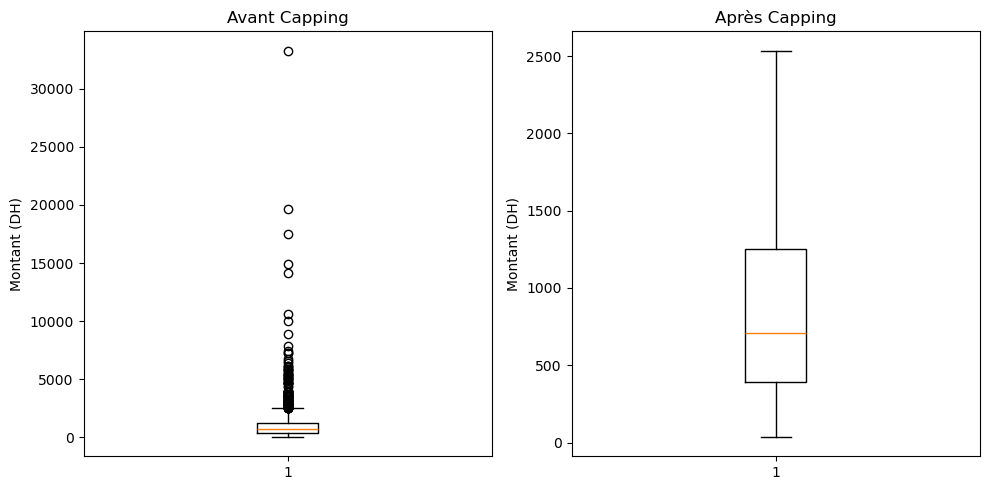

In [40]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.boxplot(X_ref["montant_dh"].dropna())
plt.title("Avant Capping")
plt.ylabel("Montant (DH)")
plt.subplot(1, 2, 2)
plt.boxplot(X_ref_capped["montant_dh"].dropna())
plt.title("Après Capping")
plt.ylabel("Montant (DH)")
plt.tight_layout()
plt.show()

## Question 18 — Comparaison des méthodes de normalisation

In [41]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
montant = X_ref[["montant_dh"]].dropna()
minmax = MinMaxScaler()
standard = StandardScaler()
robust = RobustScaler()
comparaison = pd.DataFrame({
    "Original": montant["montant_dh"].values,
    "MinMax": minmax.fit_transform(montant).flatten(),
    "Standard": standard.fit_transform(montant).flatten(),
    "Robust": robust.fit_transform(montant).flatten()
})
comparaison.head(10)

,Original,MinMax,Standard,Robust
0,419.53,0.011524,-0.453607,-0.339946
1,533.01,0.014938,-0.369626,-0.207497
2,477.87,0.013279,-0.410432,-0.271854
3,2518.08,0.074648,1.099433,2.109392
4,394.74,0.010779,-0.471953,-0.368880
5,658.53,0.018713,-0.276734,-0.060996
6,250.89,0.006452,-0.578410,-0.536776
7,421.09,0.011571,-0.452453,-0.338125
8,402.85,0.011022,-0.465951,-0.359414
9,479.71,0.013334,-0.409071,-0.269707


## Question 19 : Tableau comparatif

In [42]:
indices = [0, 1, 2, montant["montant_dh"].argmax()]
selection = montant.iloc[indices]
tableau = pd.DataFrame({
    "Type": ["Habituel", "Habituel", "Habituel", "Très élevé"],
    "Avant": selection["montant_dh"].values,
    "MinMax": minmax.transform(selection).flatten(),
    "Standard": standard.transform(selection).flatten(),
    "Robust": robust.transform(selection).flatten()
})
tableau

,Type,Avant,MinMax,Standard,Robust
0,Habituel,419.53,0.011524,-0.453607,-0.339946
1,Habituel,533.01,0.014938,-0.369626,-0.207497
2,Habituel,477.87,0.013279,-0.410432,-0.271854
3,Très élevé,33281.23,1.000000,23.865830,38.014829


## Question 20 — Comparaison des méthodes de normalisation

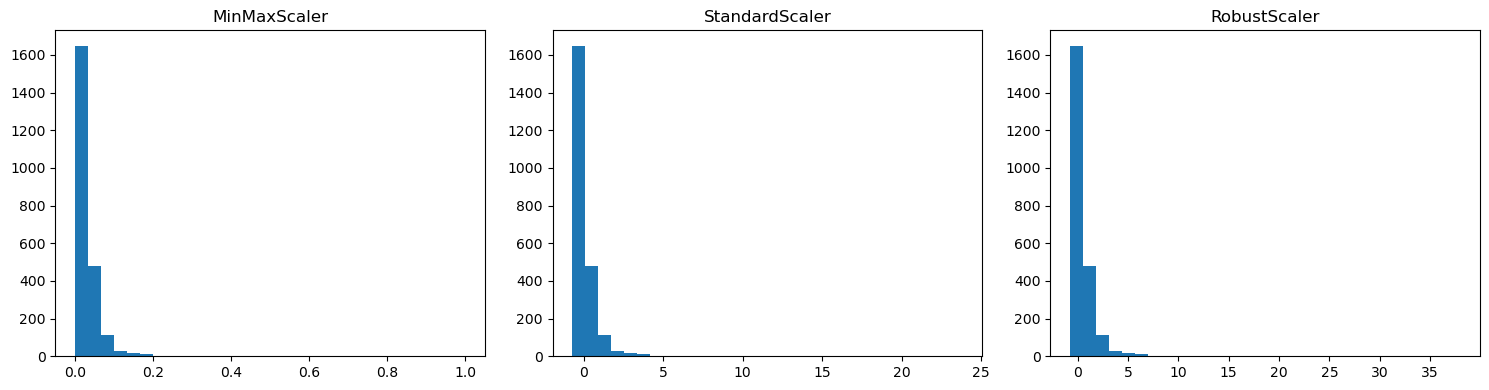

In [43]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.hist(comparaison["MinMax"], bins=30)
plt.title("MinMaxScaler")
plt.subplot(1, 3, 2)
plt.hist(comparaison["Standard"], bins=30)
plt.title("StandardScaler")
plt.subplot(1, 3, 3)
plt.hist(comparaison["Robust"], bins=30)
plt.title("RobustScaler")
plt.tight_layout()
plt.show()

## Question 21 — MinMaxScaler et nouvelles transactions

In [44]:
X_reference = np.array([[10], [20], [30]])
X_nouvelle = np.array([[40]])
scaler = MinMaxScaler()
scaler.fit(X_reference)
resultat = scaler.transform(X_nouvelle)
print("Valeur transformée :", resultat[0][0])

Valeur transformée : 1.5


# Partie 4 — Préparer des classes déséquilibrées


## Question 22 — Répartition des classes

In [45]:
print(y_ref.value_counts())
print(y_ref.value_counts(normalize=True) * 100)
rapport = y_ref.value_counts()[0] / y_ref.value_counts()[1]
print("Rapport classe 0 / classe 1 :", rapport)

fraude
0    2194
1     206
Name: count, dtype: int64
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64
Rapport classe 0 / classe 1 : 10.650485436893204


## Question 23 — RandomOverSampler

In [46]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_ref, y_ref)
print("Avant :")
print(y_ref.value_counts())
print("\nAprès RandomOverSampler :")
print(y_over.value_counts())
print("\nDimensions avant :", X_ref.shape)
print("Dimensions après :", X_over.shape)

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomOverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64

Dimensions avant : (2400, 8)
Dimensions après : (4388, 8)


## Question 24 — RandomUnderSampler

In [47]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_ref, y_ref)
print("Avant :")
print(y_ref.value_counts())
print("\nAprès RandomUnderSampler :")
print(y_under.value_counts())
print("\nDimensions avant :", X_ref.shape)
print("Dimensions après :", X_under.shape)

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomUnderSampler :
fraude
0    206
1    206
Name: count, dtype: int64

Dimensions avant : (2400, 8)
Dimensions après : (412, 8)


## Question 25 — SMOTE

In [48]:
A = np.array([2, 4])
B = np.array([6, 8])
lambda_ = 0.5
X_new = A + lambda_ * (B - A)
print("Observation A :", A)
print("Observation B :", B)
print("Observation synthétique :", X_new)

Observation A : [2 4]
Observation B : [6 8]
Observation synthétique : [4. 6.]


## Question 26 — SMOTE et variables catégorielles

SMOTE peut créer des valeurs intermédiaires non valides pour les variables catégorielles encodées en One-Hot. Pour les données mixtes (numériques et catégorielles), on utilise SMOTENC.

## Question 27 — Tableau comparatif du rééquilibrage

In [49]:
tableau_equilibrage = pd.DataFrame({
    "Avant rééquilibrage": y_ref.value_counts().sort_index(),
    "RandomOverSampler": y_over.value_counts().sort_index(),
    "RandomUnderSampler": y_under.value_counts().sort_index()
})
tableau_equilibrage.index.name = "Classe"
tableau_equilibrage

,Avant rééquilibrage,RandomOverSampler,RandomUnderSampler
Classe,,,
0,2194,2194,206
1,206,2194,206


# Partie 5 — Vérifier et enregistrer les données préparées

## Question 28 — Créer le ColumnTransformer final

In [50]:
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
pipeline_num_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
pipeline_cat_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor_final = ColumnTransformer(
    transformers=[
        ("num", pipeline_num_final, numeriques),
        ("cat", pipeline_cat_final, categorielle)
    ]
)
print("Préprocesseur final créé avec succès.")

Préprocesseur final créé avec succès.


## Question 29 — Fit et Transform

In [51]:
X_ref_final = preprocessor_final.fit_transform(X_ref)
X_verif_final = preprocessor_final.transform(X_verif)
print("X_ref_final :", X_ref_final.shape)
print("X_verif_final :", X_verif_final.shape)
print("Valeurs manquantes dans X_ref_final :",
      np.isnan(X_ref_final).sum())
print("Valeurs manquantes dans X_verif_final :",
      np.isnan(X_verif_final).sum())

X_ref_final : (2400, 18)
X_verif_final : (600, 18)
Valeurs manquantes dans X_ref_final : 0
Valeurs manquantes dans X_verif_final : 0


## Question 30 — Catégorie inconnue

In [52]:
nouvelle_transaction = X_ref.iloc[[0]].copy()
nouvelle_transaction["canal"] = "Canal_Inconnu"
resultat_nouveau = preprocessor_final.transform(nouvelle_transaction)
print("Transformation réussie !")
print("Dimensions :", resultat_nouveau.shape)

Transformation réussie !
Dimensions : (1, 18)


## Question 31 : Enregistrez le transformateur préparé avec joblib

In [53]:
import joblib
joblib.dump(preprocessor_final, "preprocessor_final.joblib")
preprocessor_charge = joblib.load("preprocessor_final.joblib")
echantillon = X_ref.iloc[:5]
avant = preprocessor_final.transform(echantillon)
apres = preprocessor_charge.transform(echantillon)
print("Résultats identiques :", np.allclose(avant, apres))

Résultats identiques : True


## Question 32 : Bilan du travail

- **Doublons :** 45 doublons ont été supprimés à partir de la colonne `id_operation`.
- **Valeurs manquantes :** Elles ont été traitées par imputation : la médiane pour les variables numériques et la modalité la plus fréquente pour les variables catégorielles.
- **Valeurs extrêmes :** La méthode IQR a détecté 146 valeurs extrêmes dans le groupe de référence pour la variable `montant_dh`. Le Capping a été étudié pour limiter leur influence.
- **Transformation des données numériques :** Le `RobustScaler` a été choisi car il est moins sensible aux valeurs extrêmes grâce à l'utilisation de la médiane et de l'IQR.
- **Transformation des données catégorielles :** `OneHotEncoder` a été utilisé pour convertir les catégories en valeurs numériques. L'option `handle_unknown="ignore"` permet de traiter les nouvelles catégories sans erreur.
- **Rééquilibrage :** RandomOverSampler a équilibré les classes en augmentant la classe minoritaire, tandis que RandomUnderSampler a réduit la classe majoritaire. Ces méthodes ont été appliquées uniquement au groupe de référence.

**Conclusion :** Ce TP m'a permis de réaliser les principales étapes du prétraitement avancé des données : suppression des doublons, traitement des valeurs manquantes, détection des valeurs extrêmes, normalisation, encodage et rééquilibrage des classes. Le transformateur final a été ajusté uniquement sur le groupe de référence afin d'éviter le Data Leakage, puis appliqué au groupe de vérification.

## Bonus A — Comparaison moyenne et médiane

In [54]:
from sklearn.impute import SimpleImputer
imputer_mean = SimpleImputer(strategy="mean")
montant_mean = imputer_mean.fit_transform(
    X_ref[["montant_dh"]]
)
imputer_median = SimpleImputer(strategy="median")
montant_median = imputer_median.fit_transform(
    X_ref[["montant_dh"]]
)
comparaison = pd.DataFrame({
    "Methode": ["Moyenne", "Mediane"],
    "Valeur_imputee": [
        imputer_mean.statistics_[0],
        imputer_median.statistics_[0]
    ]
})
comparaison

,Methode,Valeur_imputee
0,Moyenne,1032.467777
1,Mediane,710.790000


## Bonus B — SMOTENC

In [55]:
numeriques
categorielle

['canal', 'appareil', 'region', 'international']

In [56]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
import numpy as np
imputer_num = SimpleImputer(strategy="median")
X_num = imputer_num.fit_transform(X_ref[numeriques])
imputer_cat = SimpleImputer(strategy="most_frequent")
X_cat_clean = imputer_cat.fit_transform(X_ref[categorielle])
encoder = OrdinalEncoder()
X_cat = encoder.fit_transform(X_cat_clean)
X_prepare = np.hstack([X_num, X_cat])
indices_cat = [4, 5, 6, 7]
print("Dimensions :", X_prepare.shape)
print("Indices catégoriels :", indices_cat)

Dimensions : (2400, 8)
Indices catégoriels : [4, 5, 6, 7]


In [57]:
from imblearn.over_sampling import SMOTENC
smotenc = SMOTENC(
    categorical_features=indices_cat,
    random_state=42
)
X_smotenc, y_smotenc = smotenc.fit_resample(
    X_prepare, y_ref
)
print("Avant rééquilibrage :")
print(y_ref.value_counts())
print("\nAprès rééquilibrage :")
print(pd.Series(y_smotenc).value_counts())
print("\nDimensions après SMOTENC :", X_smotenc.shape)

Avant rééquilibrage :
fraude
0    2194
1     206
Name: count, dtype: int64

Après rééquilibrage :
fraude
0    2194
1    2194
Name: count, dtype: int64

Dimensions après SMOTENC : (4388, 8)


In [58]:
X_cat_smotenc = X_smotenc[:, indices_cat]
for i, colonne in enumerate(categorielle):
    print(f"\n{colonne} :")
    print(np.unique(X_cat_smotenc[:, i]))


canal :
[0. 1. 2. 3.]

appareil :
[0. 1. 2.]

region :
[0. 1. 2. 3. 4.]

international :
[0. 1.]


## -------------------------------------------FIN-------------------------------------------